In [1]:
print("ok")

ok


In [2]:
# # step 1 download the face detection model
# import urllib.request

# model_url = (
#     "https://storage.googleapis.com/mediapipe-models/"
#     "face_detector/blaze_face_short_range/float16/latest/"
#     "blaze_face_short_range.tflite"
# )

# model_path = "blaze_face_short_range.tflite"

# urllib.request.urlretrieve(model_url, model_path)

# print("Model downloaded!")

In [4]:
# load the model using mediapipe
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

model_path = "blaze_face_short_range.tflite"
BaseOptions = python.BaseOptions

FaceDetector = vision.FaceDetector

FaceDetectorOptions = vision.FaceDetectorOptions

options = FaceDetectorOptions(
    base_options=BaseOptions(
        model_asset_path=model_path
    ),
    running_mode=vision.RunningMode.IMAGE,
    min_detection_confidence=0.5
)

detector = FaceDetector.create_from_options(options)

print("Face detector initialized!")

Face detector initialized!


In [7]:
import cv2
video_path = "test_video.mp4"  # Replace with your video file path
cap = cv2.VideoCapture(video_path)

success, frame = cap.read()

cap.release()

if not success:
    raise ValueError("Could not read video frame")

rgb_frame = cv2.cvtColor(
    frame,
    cv2.COLOR_BGR2RGB
)
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb_frame
)

In [8]:
detection_result = detector.detect(mp_image)

print("Detected faces:", len(detection_result.detections))

Detected faces: 1


In [9]:
for detection in detection_result.detections:

    print("Bounding box:", detection.bounding_box)

    print("Confidence:", detection.categories[0].score)

    print("Keypoints:", detection.keypoints)

Bounding box: BoundingBox(origin_x=161, origin_y=611, width=398, height=398)
Confidence: 0.9335926175117493
Keypoints: [NormalizedKeypoint(x=0.40348750352859497, y=0.5562030076980591, label=None, score=0.0), NormalizedKeypoint(x=0.6189231276512146, y=0.5658822655677795, label=None, score=0.0), NormalizedKeypoint(x=0.5034011006355286, y=0.6365942358970642, label=None, score=0.0), NormalizedKeypoint(x=0.4923253655433655, y=0.7008268237113953, label=None, score=0.0), NormalizedKeypoint(x=0.27360087633132935, y=0.5833800435066223, label=None, score=0.0), NormalizedKeypoint(x=0.7284731268882751, y=0.6045525074005127, label=None, score=0.0)]


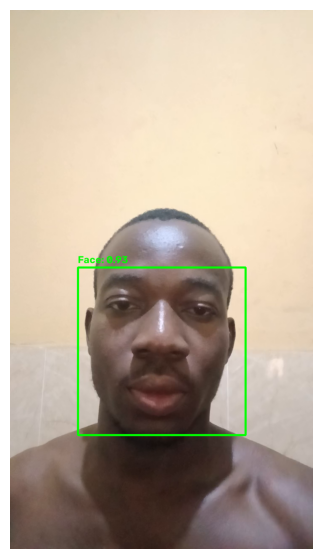

In [11]:
# let's draw the bounding boxes on the original frame and display it
import matplotlib.pyplot as plt
annotated_frame = rgb_frame.copy()

for detection in detection_result.detections:

    bbox = detection.bounding_box

    x = bbox.origin_x
    y = bbox.origin_y
    w = bbox.width
    h = bbox.height

    confidence = detection.categories[0].score

    # Draw rectangle
    cv2.rectangle(
        annotated_frame,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        3
    )

    # Draw confidence score
    label = f"Face: {confidence:.2f}"

    cv2.putText(
        annotated_frame,
        label,
        (x, max(25, y - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 0),
        2
    )

plt.figure(figsize=(10, 7))

plt.imshow(annotated_frame)

plt.axis("off")

plt.show()

Now let's process an entire video

In [12]:
video_options = FaceDetectorOptions(
    base_options=BaseOptions(
        model_asset_path=model_path
    ),
    running_mode=vision.RunningMode.VIDEO,
    min_detection_confidence=0.5
)

video_detector = FaceDetector.create_from_options(
    video_options
)

In [13]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

frame_number = 0

sample_interval = int(fps)

results = []

while True:

    success, frame = cap.read()

    if not success:
        break

    if frame_number % sample_interval == 0:

        # Convert BGR to RGB
        rgb_frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        # Convert to MediaPipe image
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb_frame
        )

        # Calculate timestamp in milliseconds
        timestamp_ms = int(
            frame_number * 1000 / fps
        )

        # Detect faces
        detection_result = video_detector.detect_for_video(
            mp_image,
            timestamp_ms
        )

        # Draw bounding boxes
        annotated_frame = rgb_frame.copy()

        for detection in detection_result.detections:

            bbox = detection.bounding_box

            x = bbox.origin_x
            y = bbox.origin_y
            w = bbox.width
            h = bbox.height

            cv2.rectangle(
                annotated_frame,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                3
            )

        results.append({
            "timestamp": timestamp_ms / 1000,
            "face_count": len(detection_result.detections),
            "image": annotated_frame
        })

    frame_number += 1

cap.release()
video_detector.close()

print("Video processing completed!")
print("Frames analyzed:", len(results))

Video processing completed!
Frames analyzed: 9


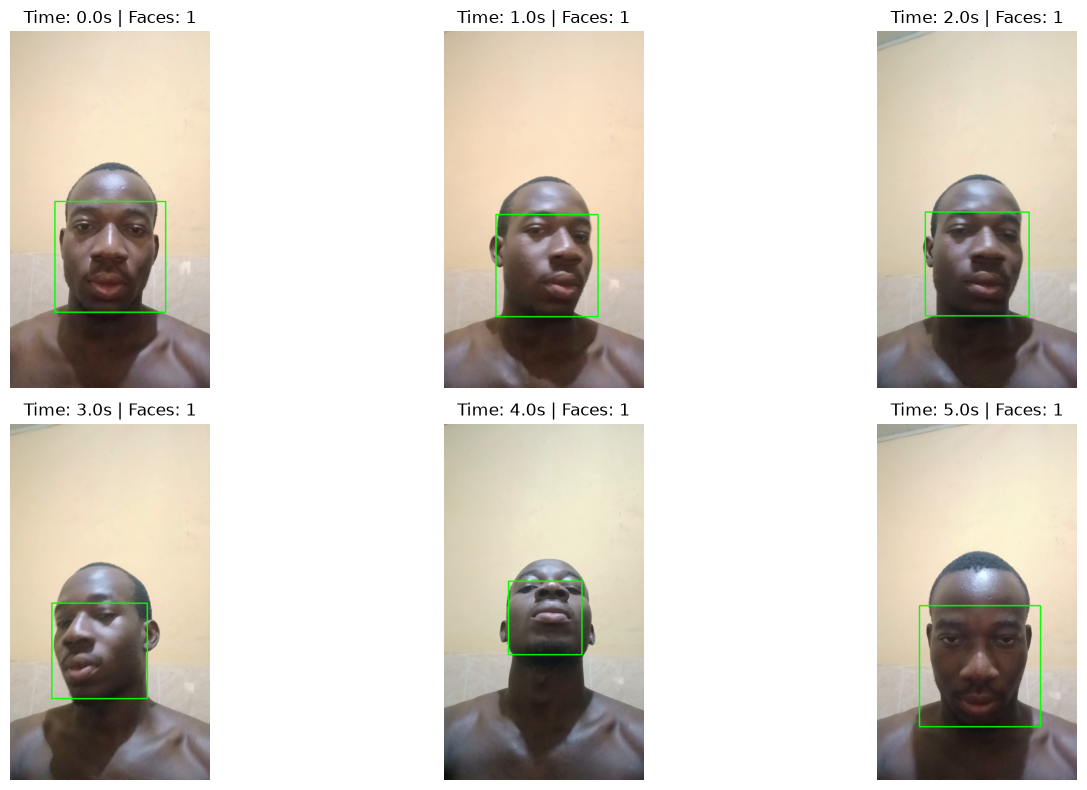

In [14]:
number_to_display = min(6, len(results))

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8)
)

for i, ax in enumerate(axes.flat):

    if i < number_to_display:

        ax.imshow(results[i]["image"])

        ax.set_title(
            f'Time: {results[i]["timestamp"]:.1f}s | '
            f'Faces: {results[i]["face_count"]}'
        )

    ax.axis("off")

plt.tight_layout()
plt.show()